# Análisis exploratorio de los viajes limpios de MiBici

**Proyecto:** Pronóstico de demanda de bicicletas por estación y hora en Guadalajara  
**Fase:** 1 - Avance de proyecto  
**Responsable:** Dante Andreas Cosgaya Morán  
**Rol:** Data Scientist  
**GitHub Issue:** #5 - EDA: análisis exploratorio de los viajes limpios  
**Periodo de análisis:** octubre de 2025 a septiembre de 2026

## Objetivo

Realizar un análisis exploratorio de los viajes de MiBici Guadalajara utilizando el conjunto de datos previamente limpiado por el equipo, con el propósito de identificar patrones temporales, espaciales y demográficos que permitan comprender el comportamiento de la demanda de bicicletas.

## Alcance

El análisis comprende:

1. Estadísticas descriptivas y verificación del dataset limpio.
2. Demanda por hora del día y día de la semana.
3. Estaciones con mayor número de salidas y llegadas.
4. Balance de movimientos entre estaciones.
5. Distribución de duración de viajes, género y edad.
6. Distribución geográfica de estaciones.
7. Identificación de patrones, anomalías y limitaciones.
8. Conclusiones y recomendaciones para el preprocesamiento posterior.

**Fuente:** Datos abiertos de MiBici Guadalajara.

**Dataset de entrada:** `data/interim/viajes_limpios.parquet`

**Catálogo de estaciones:** `data/raw/nomenclatura_2026_09.csv`

**Nota:** Este notebook utiliza los datos limpios generados por el pipeline del equipo. No modifica los archivos originales ni sustituye las reglas de limpieza existentes.

In [1]:
from IPython.display import display
import pandas as pd
import seaborn as sns
import mlflow

from mibici.cleaning import estado_git
from mibici.dataset import URL_DATOS_ABIERTOS
from mibici.config import FIGURES_DIR, INTERIM_DATA_DIR, RAW_DATA_DIR
from mibici.eda import ViajesEDA
from mibici.plots import EDAPlots

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

2026-10-24 14:57:06.489 | INFO     | mibici.config:<module>:11 - PROJ_ROOT path is: /Users/arturoflores/Library/CloudStorage/GoogleDrive-floresamaroarturo@gmail.com/My Drive/Tec de Monterrey/MLOps/mibici_project/mibici-demand


In [2]:
# Rutas de los datasets
DATASET_PATH = INTERIM_DATA_DIR / "viajes_limpios.parquet"
NOMENCLATURA_PATH = RAW_DATA_DIR / "nomenclatura_2026_09.csv"

# Cargar los viajes limpios y la nomenclatura
viajes = pd.read_parquet(DATASET_PATH)
nomenclatura = pd.read_csv(NOMENCLATURA_PATH)

# Instanciar el analizador exploratorio
eda = ViajesEDA(viajes, nomenclatura)

# Dimensiones y primeros registros
print(f"Registros: {viajes.shape[0]:,}")
print(f"Columnas: {viajes.shape[1]}")

display(viajes.head())

Registros: 4,354,416
Columnas: 12


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,mes_archivo,duracion_min,duracion_atipica,estacion_en_catalogo
0,41060015,2664376,M,1979.0,2025-10-01 00:00:26,2025-10-01 00:08:55,244,46,2025-10,8.483333,False,True
1,41060016,2371634,M,1976.0,2025-10-01 00:00:31,2025-10-01 00:07:33,31,6,2025-10,7.033333,False,True
2,41060017,4527261,M,1992.0,2025-10-01 00:00:36,2025-10-01 00:07:03,73,39,2025-10,6.450000,False,True
3,41060018,2524662,M,1996.0,2025-10-01 00:00:37,2025-10-01 00:13:20,21,248,2025-10,12.716667,False,True
4,41060026,4577155,M,1990.0,2025-10-01 00:02:38,2025-10-01 00:29:37,81,35,2025-10,26.983333,False,True


In [3]:
# Resumen de estructura y calidad del dataset limpio.
resumen_calidad = pd.DataFrame({
    "tipo_dato": viajes.dtypes.astype(str),
    "valores_nulos": viajes.isna().sum(),
    "porcentaje_nulos": viajes.isna().mean().mul(100).round(2)
})

display(resumen_calidad)

# Verificar duplicados por identificador de viaje.
duplicados = viajes["Viaje_Id"].duplicated().sum()

print(f"Viajes duplicados por ID: {duplicados:,}")
print(f"Memoria utilizada: {viajes.memory_usage(deep=True).sum() / 1024**2:,.2f} MB")

,tipo_dato,valores_nulos,porcentaje_nulos
Viaje_Id,int64,0,0.00
Usuario_Id,int64,0,0.00
Genero,object,0,0.00
Año_de_nacimiento,float64,816,0.02
Inicio_del_viaje,datetime64[ns],0,0.00
Fin_del_viaje,datetime64[ns],0,0.00
Origen_Id,int64,0,0.00
Destino_Id,int64,0,0.00
mes_archivo,object,0,0.00
duracion_min,float64,0,0.00


Viajes duplicados por ID: 0
Memoria utilizada: 714.57 MB


## 1. Estadísticas descriptivas

En esta sección se analizan las características generales de los viajes limpios de MiBici, prestando especial atención a la duración de los recorridos y a las variables de calidad conservadas después del proceso de limpieza.

Se utilizan medidas de tendencia central y dispersión para identificar el comportamiento general de los datos y posibles valores extremos. Los resultados servirán como referencia para los análisis temporales, espaciales y demográficos posteriores.

In [4]:
# Validar el período temporal del dataset limpio.
fecha_minima = viajes["Inicio_del_viaje"].min()
fecha_maxima = viajes["Inicio_del_viaje"].max()

periodo_inicio = pd.Timestamp("2025-10-01")
periodo_fin = pd.Timestamp("2026-10-01")

print(f"Primer viaje: {fecha_minima}")
print(f"Último viaje: {fecha_maxima}")

assert fecha_minima >= periodo_inicio, (
    "Existen viajes anteriores a octubre de 2025."
)

assert fecha_maxima < periodo_fin, (
    "Existen viajes posteriores a septiembre de 2026."
)

print("Validación del período temporal: correcta.")

Primer viaje: 2025-10-01 00:00:26
Último viaje: 2026-09-30 23:59:48
Validación del período temporal: correcta.


In [5]:
# Estadísticas descriptivas de la duración de los viajes.
estadisticas_duracion = viajes["duracion_min"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(estadisticas_duracion.to_frame(name="duracion_min"))

# Resumen de las banderas de calidad.
print("Viajes con duración atípica:")
print(viajes["duracion_atipica"].value_counts())

print("\nViajes según pertenencia al catálogo de estaciones:")
print(viajes["estacion_en_catalogo"].value_counts())

,duracion_min
count,4.354416e+06
mean,1.130689e+01
std,8.893722e+00
min,3.333333e-02
25%,5.966667e+00
50%,9.616667e+00
75%,1.493333e+01
90%,2.090000e+01
95%,2.463333e+01
99%,3.366667e+01


Viajes con duración atípica:
duracion_atipica
False    4353919
True         497
Name: count, dtype: int64

Viajes según pertenencia al catálogo de estaciones:
estacion_en_catalogo
True     4350528
False       3888
Name: count, dtype: int64


### Interpretación de las estadísticas descriptivas

El análisis de los 4,354,416 viajes limpios muestra una duración promedio de 11.31 minutos y una mediana de 9.62 minutos. Esta diferencia sugiere una distribución asimétrica hacia la derecha, donde los recorridos más largos incrementan el promedio general.

El 50 % central de los viajes presenta duraciones entre 5.97 y 14.93 minutos. Asimismo, el percentil 95 indica que la gran mayoría de los recorridos tiene una duración inferior a 24.63 minutos.

Se identificaron 497 viajes marcados con duración atípica, equivalentes aproximadamente al 0.0114 % del total. Estos registros se conservaron conforme a las reglas de limpieza establecidas por el equipo y deberán considerarse al analizar la distribución de duraciones.

Por otra parte, 3,888 viajes (0.0893 %) presentan al menos una estación que no corresponde al catálogo de nomenclatura utilizado. Esta situación representa una limitación para el análisis geográfico, ya que algunas estaciones podrían no contar con coordenadas disponibles.

En general, el dataset presenta una proporción reducida de valores faltantes y no contiene identificadores de viaje duplicados. Estos resultados permiten continuar con el análisis exploratorio, conservando las observaciones originales del conjunto de datos limpio.

## 2. Análisis de demanda temporal

En esta sección se analiza la distribución de los viajes según su hora de inicio y el día de la semana.

El objetivo es identificar patrones temporales de uso del sistema MiBici, reconocer períodos de mayor demanda y obtener información que contribuya al desarrollo del modelo de pronóstico por estación y hora.

In [6]:
# Calcular la cantidad de viajes iniciados en cada hora del día usando ViajesEDA
demanda_por_hora = eda.obtener_demanda_por_hora()

# Presentar los resultados
resumen_demanda_hora = pd.DataFrame({
    "hora": demanda_por_hora.index,
    "total_viajes": demanda_por_hora.values
})

display(resumen_demanda_hora)

print(f"Hora de mayor demanda: {demanda_por_hora.idxmax():02d}:00")
print(f"Viajes en la hora de mayor demanda: {demanda_por_hora.max():,}")

print(f"Hora de menor demanda: {demanda_por_hora.idxmin():02d}:00")
print(f"Viajes en la hora de menor demanda: {demanda_por_hora.min():,}")

,hora,total_viajes
0,0,28596
1,1,93
2,2,10
3,3,1
4,4,9
5,5,37894
6,6,128295
7,7,245439
8,8,325978
9,9,239644


Hora de mayor demanda: 18:00
Viajes en la hora de mayor demanda: 387,839
Hora de menor demanda: 03:00
Viajes en la hora de menor demanda: 1


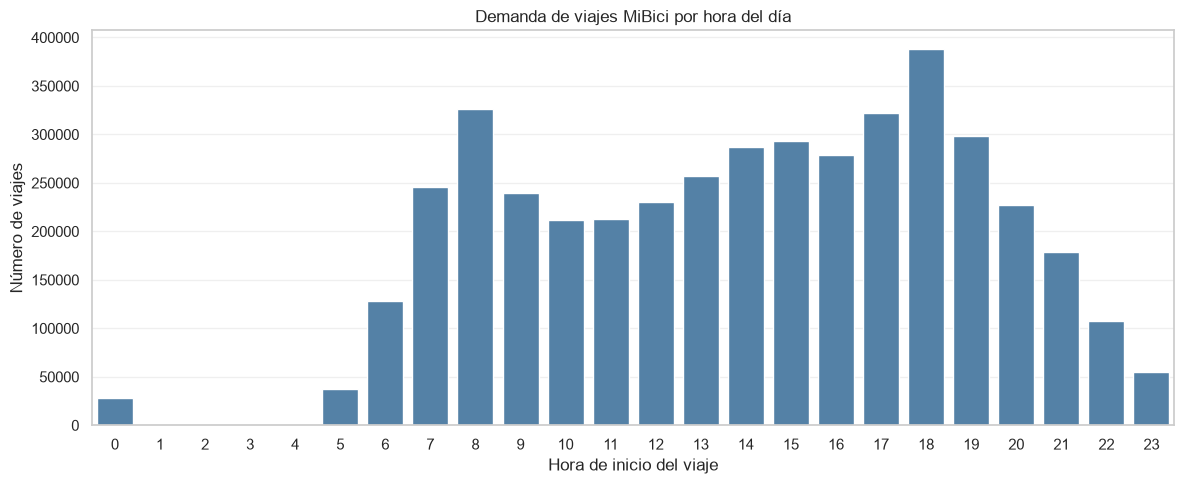

In [7]:
# Visualizar y guardar la distribución horaria desde EDAPlots
fig = EDAPlots.graficar_demanda_por_hora(
    demanda_por_hora,
    ruta_guardado=FIGURES_DIR / "eda_demanda_por_hora.png"
)

### Interpretación de la demanda por hora

La distribución horaria de los viajes muestra dos períodos de mayor actividad. El primero ocurre durante la mañana, con un máximo de 325,978 viajes a las 08:00, mientras que el segundo se presenta por la tarde, alcanzando 387,839 viajes a las 18:00.

Este comportamiento sugiere que una parte importante de la demanda podría estar relacionada con desplazamientos hacia centros de trabajo, instituciones educativas y otras actividades cotidianas. Sin embargo, esta interpretación constituye una hipótesis, ya que el dataset no incluye información sobre el propósito de los viajes.

Durante la madrugada, especialmente entre las 01:00 y las 04:00, la actividad es prácticamente nula, con valores de entre 1 y 93 viajes por hora acumulados durante todo el período analizado. Este comportamiento podría estar relacionado con restricciones en los horarios de operación del servicio, aunque sería necesario consultar información oficial para confirmar esa explicación.

Esta observación es importante para el modelado de la demanda, ya que la malla horaria utilizada para construir las variables de predicción incluye también las horas de madrugada con demanda igual a cero. Por ello, el modelo deberá distinguir entre períodos de baja actividad y posibles restricciones operativas, evitando interpretar automáticamente los valores nulos de demanda como ausencia de interés de los usuarios. Asimismo, será necesario considerar estas horas al evaluar las predicciones, debido a su comportamiento significativamente diferente del observado durante las horas de mayor actividad.

Los resultados muestran que la hora del día es una variable relevante para analizar y posteriormente pronosticar la demanda de bicicletas. También será importante estudiar si estos patrones cambian según el día de la semana y la estación de origen.

### Demanda por día de la semana

Se analiza la cantidad de viajes iniciados en cada día de la semana, utilizando la fecha de inicio de los recorridos.

Este análisis permitirá identificar diferencias en los patrones de uso entre días laborales y fines de semana, así como determinar qué días presentan mayor y menor actividad durante el período estudiado.

In [8]:
# Resumen de demanda semanal normalizado por días observados usando ViajesEDA
resumen_demanda_dia = eda.obtener_demanda_por_dia_semana()

display(resumen_demanda_dia)

# Identificar los días de mayor y menor demanda promedio
dia_mayor_demanda = resumen_demanda_dia["promedio_viajes_dia"].idxmax()
dia_menor_demanda = resumen_demanda_dia["promedio_viajes_dia"].idxmin()

print(
    f"Día de mayor demanda promedio: "
    f"{resumen_demanda_dia.loc[dia_mayor_demanda, 'dia_semana']}"
)
print(
    f"Promedio de viajes: "
    f"{resumen_demanda_dia.loc[dia_mayor_demanda, 'promedio_viajes_dia']:,.2f}"
)
print(
    f"Día de menor demanda promedio: "
    f"{resumen_demanda_dia.loc[dia_menor_demanda, 'dia_semana']}"
)
print(
    f"Promedio de viajes: "
    f"{resumen_demanda_dia.loc[dia_menor_demanda, 'promedio_viajes_dia']:,.2f}"
)

,dia_semana,total_viajes,dias_observados,promedio_viajes_dia
0,Lunes,647665,52,12455.096154
1,Martes,706718,52,13590.730769
2,Miércoles,713272,53,13457.962264
3,Jueves,680840,52,13093.076923
4,Viernes,667109,52,12829.019231
5,Sábado,500044,52,9616.230769
6,Domingo,438768,52,8437.846154


Día de mayor demanda promedio: Martes
Promedio de viajes: 13,590.73
Día de menor demanda promedio: Domingo
Promedio de viajes: 8,437.85


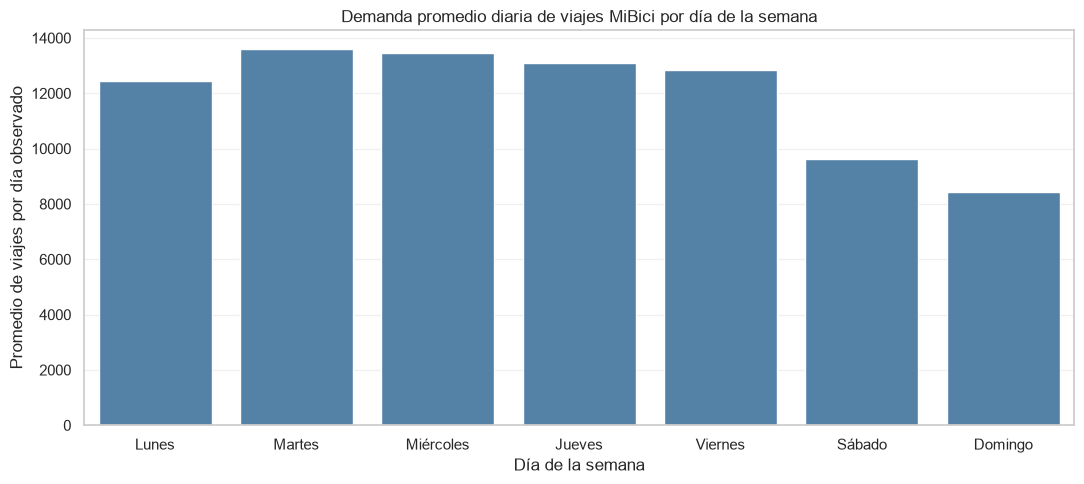

In [9]:
# Visualizar y guardar la demanda diaria desde EDAPlots
fig = EDAPlots.graficar_demanda_por_dia_semana(
    resumen_demanda_dia,
    ruta_guardado=FIGURES_DIR / "eda_demanda_por_dia.png"
)

### Interpretación de la demanda semanal

El análisis muestra que la demanda de MiBici se concentra principalmente entre lunes y viernes. Aunque el miércoles presenta el mayor volumen acumulado de viajes (713,272), este resultado está influido por la cantidad de días observados durante el período, que incluye 53 miércoles y 52 días de cada uno de los demás días de la semana.

Al normalizar los viajes por el número de días observados, el martes presenta la mayor demanda promedio, con 13,590.73 viajes diarios, seguido del miércoles, con 13,457.96. Esto permite realizar una comparación más representativa del comportamiento semanal del servicio.

Por otra parte, el domingo registra la menor demanda promedio, con 8,437.85 viajes diarios, seguido del sábado, con 9,616.23. Esta diferencia evidencia una mayor utilización del sistema durante los días laborales.

Para el modelado de la demanda, estos resultados indican que el día de la semana es una variable temporal relevante. Asimismo, la normalización por días observados evita interpretar diferencias en la cantidad de fechas disponibles como cambios reales en la intensidad de uso.

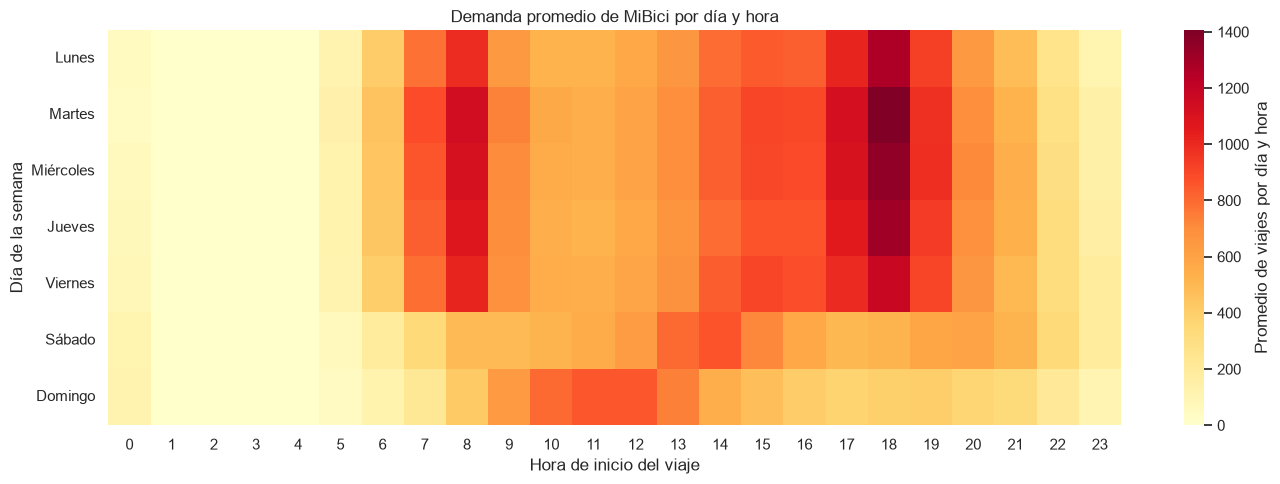

In [10]:
# Matriz normalizada día x hora usando ViajesEDA
matriz_promedio_dia_hora = eda.obtener_matriz_dia_hora()

# Generar y guardar el mapa de calor desde EDAPlots
fig = EDAPlots.graficar_mapa_calor_dia_hora(
    matriz_promedio_dia_hora,
    ruta_guardado=FIGURES_DIR / "eda_demanda_dia_hora.png"
)

### Interpretación de la demanda por día y hora

El mapa de calor muestra patrones temporales distintos entre días laborales y fines de semana. De lunes a viernes se observan dos concentraciones principales de demanda: una durante la mañana, alrededor de las 07:00 y 08:00, y otra por la tarde, especialmente entre las 17:00 y 18:00.

El mayor nivel de demanda promedio se presenta en días laborales al final de la jornada, particularmente cerca de las 18:00. Este patrón es consistente con desplazamientos recurrentes asociados a actividades cotidianas como trabajo o estudio, aunque el dataset no permite confirmar directamente el propósito de los viajes.

Durante el fin de semana la distribución cambia. El sábado presenta una actividad más extendida a lo largo del día, mientras que el domingo concentra una mayor proporción de viajes en horas medias, con menor intensidad en comparación con los días laborales.

Estos resultados confirman que tanto la hora del día como el día de la semana son variables fundamentales para comprender y posteriormente pronosticar la demanda de bicicletas en MiBici.

## 3. Estaciones con mayor número de salidas y llegadas

En esta sección se identifican las estaciones que concentran el mayor número de viajes iniciados y finalizados.

El objetivo es reconocer los puntos con mayor actividad dentro del sistema MiBici y detectar posibles concentraciones espaciales de la demanda.

In [29]:
print(f"Estaciones en el catálogo: {len(nomenclatura)}")
print(f"IDs duplicados: {nomenclatura['id'].duplicated().sum()}")
print(f"IDs nulos: {nomenclatura['id'].isna().sum()}")

eda.validar_catalogo_estaciones()

print("Validación del catálogo de estaciones: correcta.")

Estaciones en el catálogo: 484
IDs duplicados: 0
IDs nulos: 0
Validación del catálogo de estaciones: correcta.


In [11]:
# Top 10 estaciones de salida y llegada usando ViajesEDA
top_salidas, top_llegadas = eda.obtener_top_estaciones(top_n=10)

print("Top 10 estaciones con más salidas:")
display(top_salidas)

print("Top 10 estaciones con más llegadas:")
display(top_llegadas)

Top 10 estaciones con más salidas:


,id,name,total_salidas
0,51,(GDL-049) Lopez Cotilla / Penitenciaría,92399
1,35,(GDL-033) Av. Hidalgo / C. Pedro Loza,72639
2,271,(GDL-198) Av. Alcalde / C. Hospital,67605
3,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,61592
4,50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,51088
5,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,50610
6,52,(GDL-050) C.Pedro Moreno /Federalismo,50319
7,54,(GDL-052) Av. Juarez /16 de Septiembre,48006
8,38,(GDL-036) C. Marcos Castellanos/ C. Morelos,39531
9,260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,37603


Top 10 estaciones con más llegadas:


,id,name,total_llegadas
0,51,(GDL-049) Lopez Cotilla / Penitenciaría,107559
1,35,(GDL-033) Av. Hidalgo / C. Pedro Loza,85086
2,271,(GDL-198) Av. Alcalde / C. Hospital,59038
3,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,56165
4,50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,52258
5,54,(GDL-052) Av. Juarez /16 de Septiembre,50113
6,52,(GDL-050) C.Pedro Moreno /Federalismo,48059
7,260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,44968
8,38,(GDL-036) C. Marcos Castellanos/ C. Morelos,40097
9,157,(GDL-090) Calz. Federalismo / C. Durango,35790


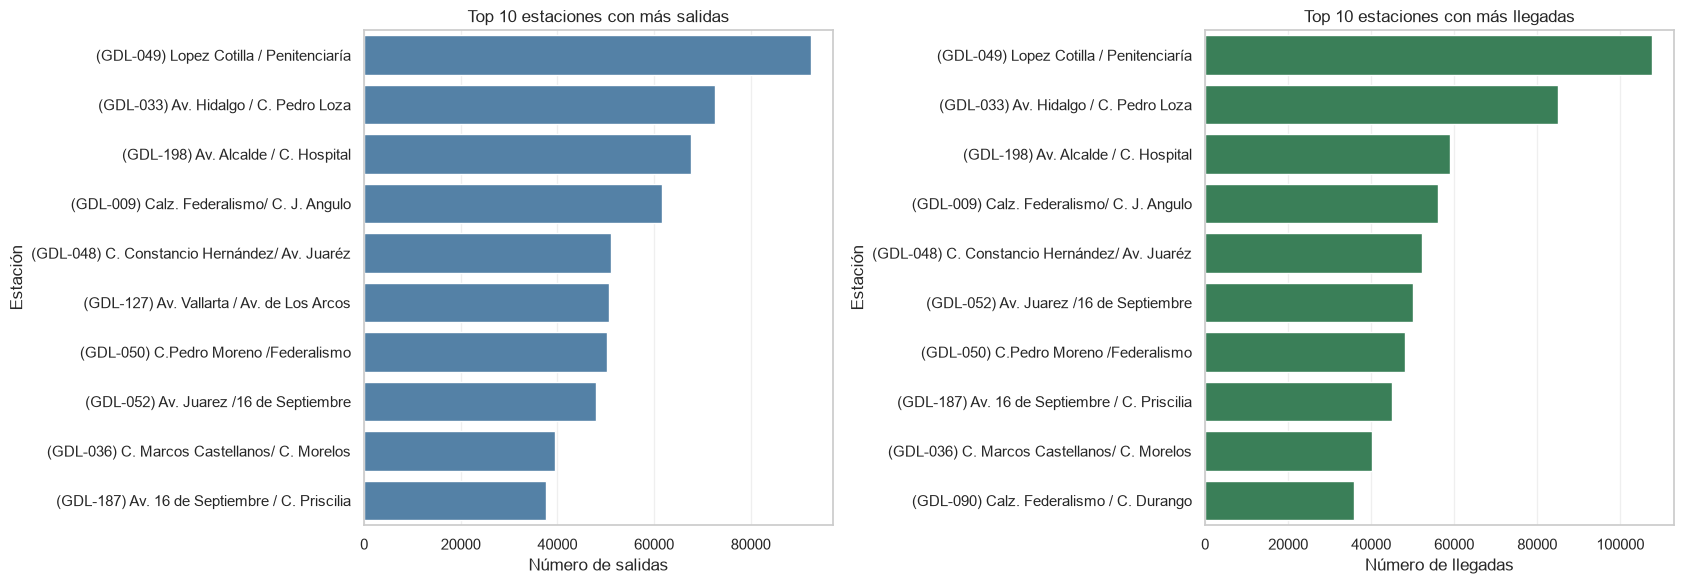

In [12]:
# Visualizar y guardar las top estaciones desde EDAPlots
fig = EDAPlots.graficar_top_estaciones(
    top_salidas,
    top_llegadas,
    ruta_guardado=FIGURES_DIR / "eda_top_estaciones.png"
)

### Interpretación de las estaciones con mayor actividad

El análisis muestra que las estaciones 51, 35 y 271 concentran los mayores volúmenes de salidas y llegadas durante el período estudiado.

La estación 51, ubicada en López Cotilla y Penitenciaría, registra 92,399 salidas y 107,559 llegadas, posicionándose como la estación con mayor actividad en ambos indicadores.

La estación 35, ubicada en Av. Hidalgo y Pedro Loza, también presenta un volumen importante, con 72,639 salidas y 85,086 llegadas.

Por su parte, la estación 271, ubicada en Av. Alcalde y Hospital, registra 67,605 salidas y 59,038 llegadas.

Nueve estaciones aparecen en ambos rankings, lo que indica que buena parte de la actividad se concentra en un conjunto común de estaciones.

Las diferencias entre salidas y llegadas sugieren posibles desequilibrios en los movimientos de bicicletas. Sin embargo, no permiten determinar por sí solas si una estación se encuentra vacía o llena, ya que también intervienen factores como la capacidad, disponibilidad y redistribución operativa de bicicletas.

## 4. Balance de movimientos por estación

Se analiza la diferencia entre el número de llegadas y salidas de cada estación para identificar posibles desequilibrios en los flujos de bicicletas.

Un balance positivo indica que una estación registra más llegadas que salidas, mientras que un balance negativo representa una mayor cantidad de salidas.

Este indicador permite identificar estaciones que podrían requerir atención operativa, aunque no representa directamente su ocupación o disponibilidad real.

In [13]:
# Balance por estación usando ViajesEDA
balance_estaciones = eda.obtener_balance_estaciones()

# Identificar los mayores desequilibrios
top_acumulacion = balance_estaciones.nlargest(10, "balance_neto")
top_vaciamiento = balance_estaciones.nsmallest(10, "balance_neto")

print("Estaciones con mayor balance positivo:")
display(top_acumulacion)

print("Estaciones con mayor balance negativo:")
display(top_vaciamiento)

print(
    f"Balance neto total: "
    f"{balance_estaciones['balance_neto'].sum():,}"
)

Estaciones con mayor balance positivo:


,id,salidas,llegadas,balance_neto,name,dpcapacity
0,51,92399,107559,15160,(GDL-049) Lopez Cotilla / Penitenciaría,39.0
1,35,72639,85086,12447,(GDL-033) Av. Hidalgo / C. Pedro Loza,15.0
145,341,11196,20838,9642,(ZPN-070)Av. Avila Camacho / Av. Patria,19.0
24,56,27043,34956,7913,(GDL-054) Av. Juárez / Calz. Independencia,27.0
9,260,37603,44968,7365,(GDL-187) Av. 16 de Septiembre / C. Priscilia,15.0
138,384,11698,18817,7119,(GDL-252) C. Calpulalpan / C. Independencia,23.0
46,78,20922,27546,6624,(GDL-076) Calz. Revolución / C. San Fernando,19.0
183,387,8891,15012,6121,(GDL-267) C. Diego Rivera / C. Sanganguey,19.0
36,42,22917,28911,5994,(GDL-040) C. Morelos / C. Progreso,19.0
98,296,14527,20441,5914,(ZPN-056) Av. M. Ávila Camacho / C. San Jorge,15.0


Estaciones con mayor balance negativo:


,id,salidas,llegadas,balance_neto,name,dpcapacity
5,194,50610,23484,-27126,(GDL-127) Av. Vallarta / Av. de Los Arcos,19.0
2,271,67605,59038,-8567,(GDL-198) Av. Alcalde / C. Hospital,31.0
56,288,19718,13630,-6088,(ZPN-048) Av. J. Parres Arias / Prol. López C,31.0
3,11,61592,56165,-5427,(GDL-009) Calz. Federalismo/ C. J. Angulo,23.0
66,197,17962,14153,-3809,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta,15.0
124,201,12376,9361,-3015,(GDL-134) C. Agustín Yáñez / C. Fco Ugarte,19.0
62,199,18570,15587,-2983,(GDL-132) C. Lope de Vega / Av. La Paz,15.0
30,196,24316,21358,-2958,(GDL-129) C. Lope de Vega / Av. Vallarta,23.0
78,253,16847,14078,-2769,(GDL-156) C. Duque de Rivas/ C. López Cotilla,15.0
119,198,12613,9844,-2769,(GDL-131) C. Emilio Castelar / Av. La Paz,19.0


Balance neto total: 0


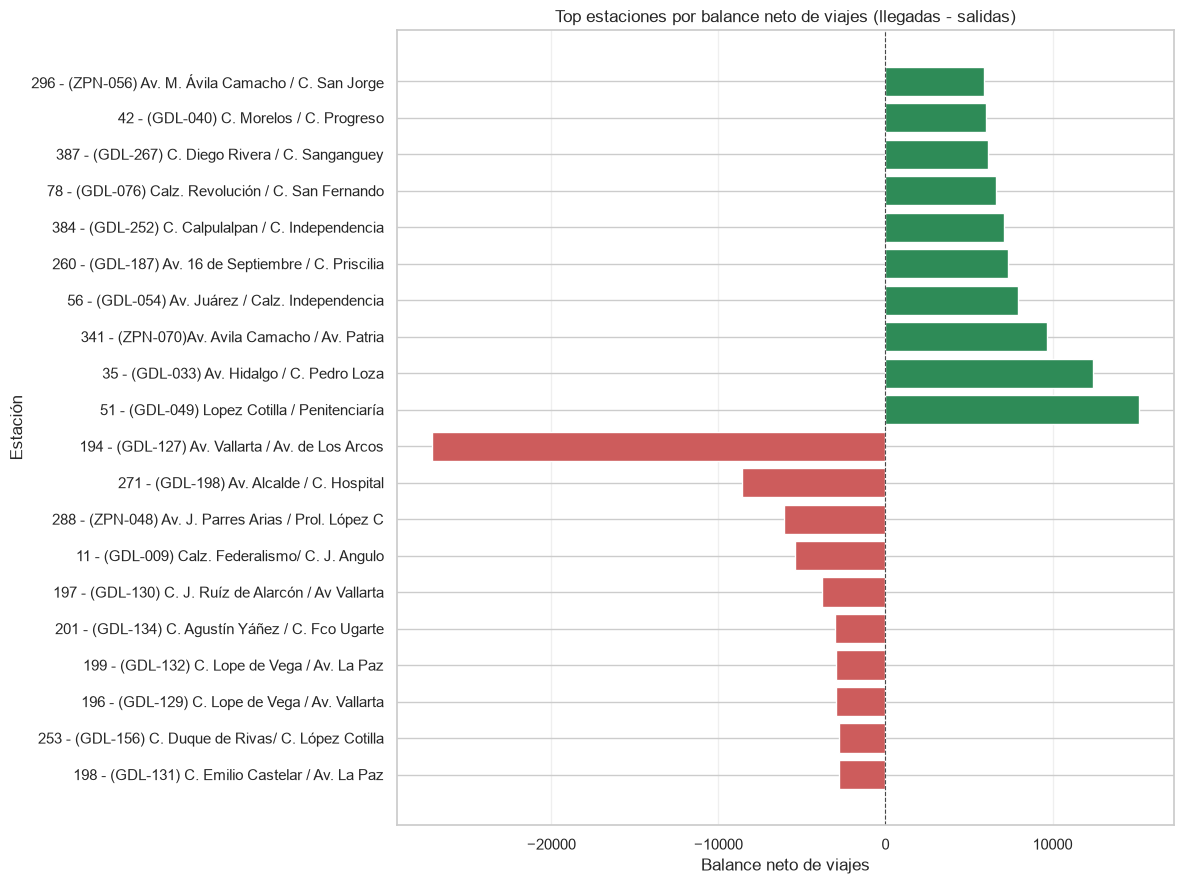

In [14]:
# Preparar datos destacados (top 10 acumulación y top 10 vaciamiento)
balance_destacado = pd.concat([top_vaciamiento.iloc[::-1], top_acumulacion]).copy()
balance_destacado["etiqueta"] = (
    balance_destacado["id"].astype(str) + " - " + balance_destacado["name"].fillna("Desconocida")
)

fig = EDAPlots.graficar_balance_estaciones(
    balance_destacado,
    ruta_guardado=FIGURES_DIR / "eda_balance_estaciones.png"
)

### Interpretación del balance de movimientos por estación

El análisis del balance neto muestra diferencias importantes entre las estaciones de MiBici. La estación 194, ubicada en Av. Vallarta y Av. de los Arcos, presenta el mayor balance negativo, con 27,126 salidas adicionales respecto a las llegadas.

Por otra parte, la estación 51, ubicada en López Cotilla y Penitenciaría, registra el mayor balance positivo, con 15,160 llegadas más que salidas. También destacan las estaciones 35 y 341, con balances positivos de 12,447 y 9,642 movimientos, respectivamente.

El balance neto total del sistema es cero, lo cual confirma que cada viaje contabilizado aporta una salida y una llegada.

Estos resultados permiten identificar estaciones con posibles necesidades de rebalanceo. Sin embargo, los balances acumulados no representan directamente la ocupación real, debido a que no se cuenta con información sobre disponibilidad histórica ni movimientos operativos de redistribución.

Para etapas posteriores se recomienda analizar los balances por hora y día de la semana, con el propósito de identificar desequilibrios temporales relevantes para el pronóstico de demanda.

## 5. Distribución de duración de viajes y características demográficas

En esta sección se analizan las distribuciones de duración de los recorridos, género y edad estimada de los usuarios.

El objetivo es comprender las características de los viajes y de sus usuarios, identificar posibles valores atípicos y reconocer patrones que puedan orientar decisiones posteriores de preprocesamiento.

### Distribución de duración de los viajes

Se utiliza un histograma para visualizar la concentración de duraciones y un diagrama de caja para identificar su dispersión. Para facilitar la lectura, las visualizaciones se limitan al percentil 99, conservando todos los registros en el dataset original.

Límite de visualización (P99): 33.67 minutos
Viajes mostrados: 4,310,942
Viajes fuera del rango visualizado: 43,474


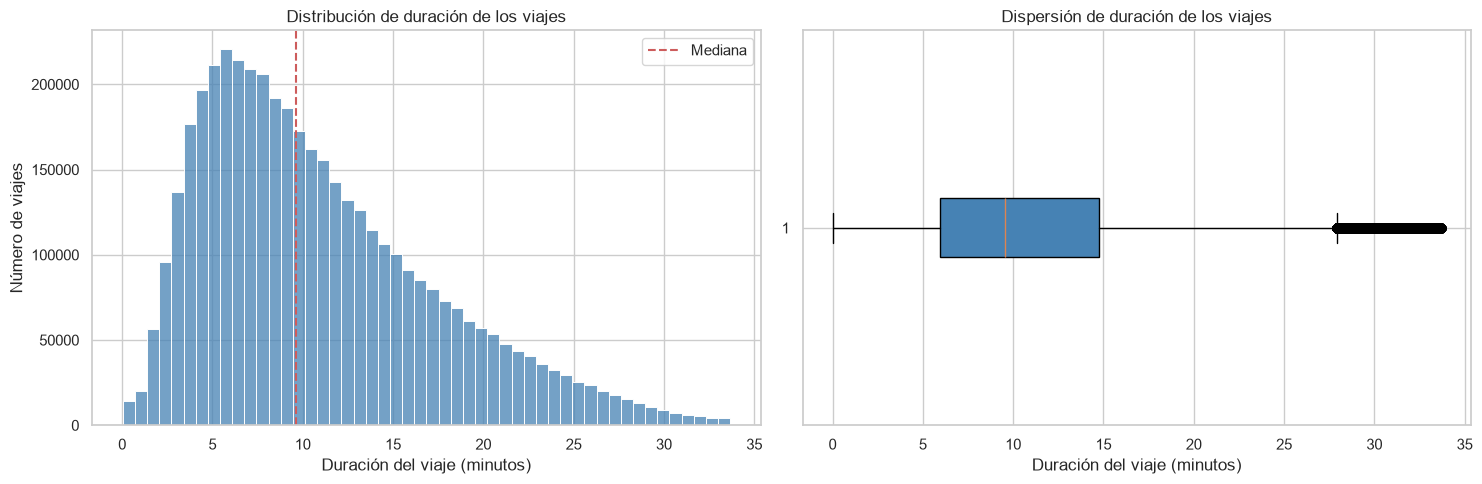

In [15]:
duraciones_visibles, limite_duracion, fuera_rango = eda.obtener_duraciones_visibles()
mediana = viajes["duracion_min"].median()

fig = EDAPlots.graficar_distribucion_duracion(
    duraciones_visibles, 
    mediana, 
    ruta_guardado=FIGURES_DIR / "eda_distribucion_duracion.png"
)

print(f"Límite de visualización (P99): {limite_duracion:.2f} minutos")
print(f"Viajes mostrados: {len(duraciones_visibles):,}")
print(f"Viajes fuera del rango visualizado: {fuera_rango:,}")

### Interpretación de la distribución de duración

La distribución de duración de los viajes presenta una concentración importante en recorridos cortos, principalmente entre 5 y 8 minutos. El histograma muestra una distribución asimétrica hacia la derecha, con una disminución gradual de la frecuencia conforme aumenta la duración.

La duración mediana es de 9.62 minutos, mientras que la media alcanza 11.31 minutos. Esta diferencia confirma que los viajes más largos incrementan el promedio general.

El diagrama de caja permite identificar observaciones que se alejan del comportamiento central de la distribución. Sin embargo, estos valores atípicos estadísticos no necesariamente representan registros inválidos.

Para facilitar la visualización se utilizó el percentil 99, equivalente a 33.67 minutos. De esta manera se representan 4,310,942 viajes, mientras que 43,474 quedan fuera del rango mostrado, sin ser eliminados del conjunto de datos.

Es importante distinguir este criterio visual de la variable `duracion_atipica`, que identifica 497 viajes conforme a las reglas de limpieza implementadas por el equipo.

Los resultados sugieren considerar medidas estadísticas robustas, como la mediana y el rango intercuartílico, al analizar la duración de los recorridos en etapas posteriores.

,genero,total_viajes,porcentaje
0,M,3140476,72.121635
1,F,1181892,27.142377
2,desconocido,32048,0.735988


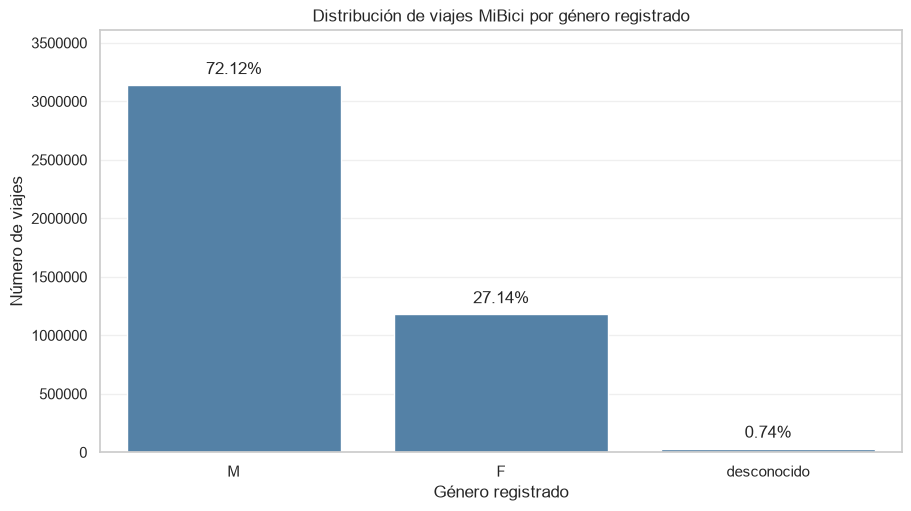

In [ ]:
# Distribución por género usando ViajesEDA
distribucion_genero = eda.obtener_distribucion_genero()
display(distribucion_genero)

fig = EDAPlots.graficar_distribucion_genero(
    distribucion_genero, 
    ruta_guardado=FIGURES_DIR / "eda_distribucion_genero.png"
)

### Interpretación de la distribución por género

El análisis muestra que el 72.12 % de los viajes corresponde a registros clasificados como masculinos, mientras que el 27.14 % corresponde a registros femeninos. El 0.74 % restante se encuentra clasificado como desconocido.

Esta diferencia indica una mayor participación de los viajes registrados en la categoría masculina dentro del período estudiado. Sin embargo, los porcentajes representan viajes y no usuarios únicos, por lo que no deben interpretarse directamente como la composición demográfica de todas las personas que utilizan MiBici.

La categoría desconocido comprende 32,048 registros que fueron conservados durante la limpieza para evitar asignar valores demográficos sin evidencia.

Estos resultados permiten describir las características de los viajes, aunque el género registrado por sí solo no demuestra una relación causal con la demanda del sistema.

,edad_estimada
count,4.353600e+06
mean,3.512051e+01
std,1.123463e+01
min,1.600000e+01
25%,2.700000e+01
50%,3.200000e+01
75%,4.100000e+01
90%,5.300000e+01
95%,5.700000e+01
99%,6.700000e+01


Viajes con edad disponible: 4,353,600
Viajes sin edad disponible: 816
Edad mínima estimada: 16
Edad máxima estimada: 87


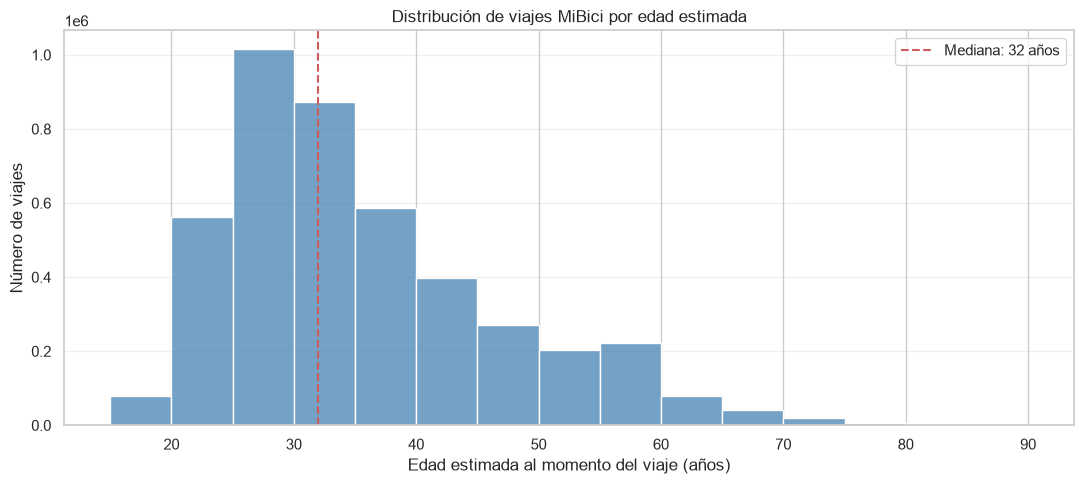

In [31]:
# Edades estimadas y estadísticas descriptivas usando ViajesEDA
edades_estimadas = eda.obtener_edades_estimadas()
edades_validas = edades_estimadas.dropna()

estadisticas_edad = edades_validas.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
display(estadisticas_edad.to_frame(name="edad_estimada"))

print(f"Viajes con edad disponible: {len(edades_validas):,}")
print(f"Viajes sin edad disponible: {edades_estimadas.isna().sum():,}")
print(f"Edad mínima estimada: {edades_validas.min():.0f}")
print(f"Edad máxima estimada: {edades_validas.max():.0f}")

fig = EDAPlots.graficar_distribucion_edad(
    edades_validas, 
    ruta_guardado=FIGURES_DIR / "eda_distribucion_edad.png"
)

### Interpretación de la distribución de edad

El análisis de edad estimada muestra que la mayor concentración de viajes corresponde a personas de entre 25 y 35 años, destacando especialmente el intervalo de 25 a 30 años.

La edad promedio estimada es de 35.12 años y la mediana es de 32 años. El 50 % central de los viajes corresponde a edades entre 27 y 41 años, lo que indica una presencia importante de adultos jóvenes en los registros del sistema.

La distribución presenta asimetría hacia la derecha, con una disminución progresiva en el número de viajes conforme aumenta la edad.

Se identificaron 816 viajes sin información de año de nacimiento. Estos registros fueron excluidos únicamente del cálculo de estadísticas de edad, sin eliminarlos del dataset original.

Es importante señalar que las edades son aproximadas y que la distribución representa viajes realizados, no usuarios únicos. Por lo tanto, una misma persona puede contribuir con múltiples observaciones.

## 6. Distribución geográfica de estaciones

En esta sección se analiza la distribución espacial de las estaciones de MiBici a partir de sus coordenadas geográficas.

Se utiliza la nomenclatura de septiembre de 2026 para relacionar las estaciones con el volumen de salidas y llegadas registrado entre octubre de 2025 y septiembre de 2026.

El objetivo es identificar la ubicación de las estaciones y reconocer posibles concentraciones geográficas de actividad.

Debe considerarse que el catálogo corresponde a un mes específico y puede no representar todas las estaciones que operaron durante el período completo.

Estaciones con movimientos: 469
Estaciones con coordenadas válidas: 469
Estaciones sin coordenadas válidas: 0


,id,latitude,longitude,total_movimientos
0,2,20.666378,-103.348820,36065
1,3,20.667228,-103.366000,30893
2,4,20.667690,-103.368252,39458
3,5,20.691847,-103.362549,36403
4,6,20.681158,-103.339363,24114


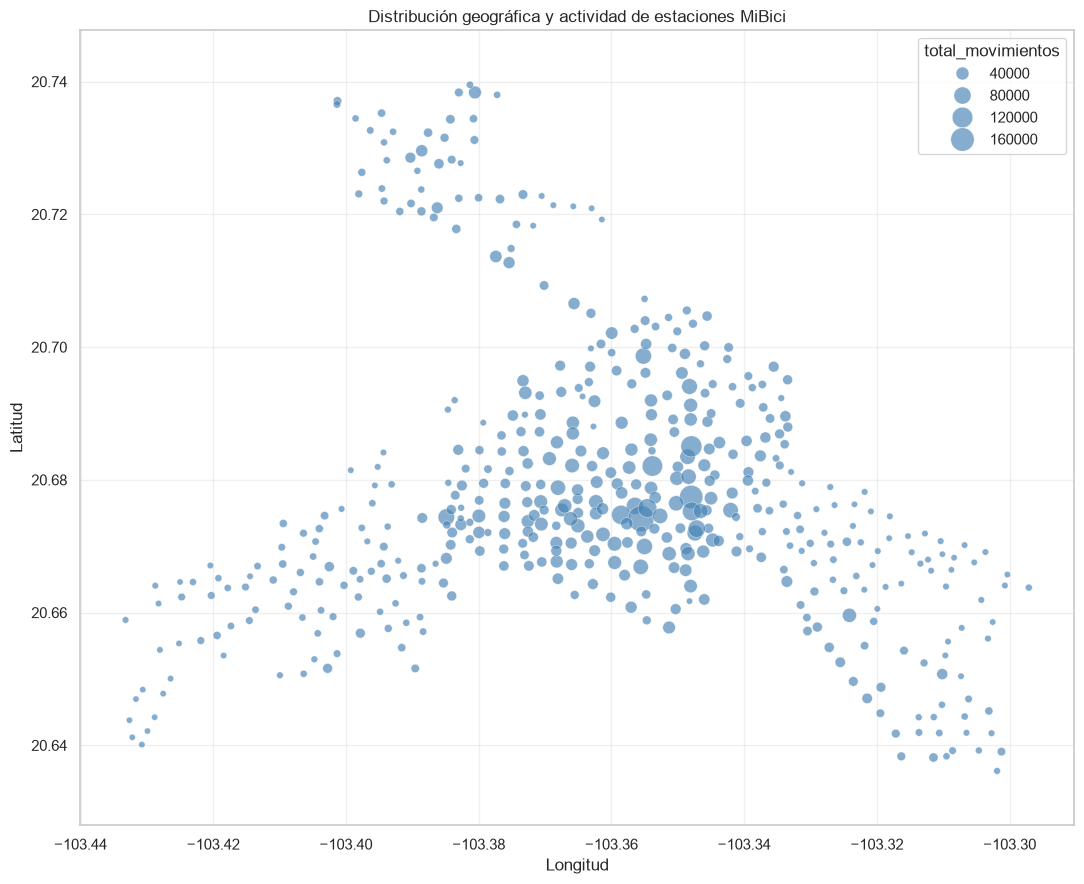

In [32]:
# Distribución geográfica y actividad por estación usando ViajesEDA
estaciones_mapa = eda.obtener_actividad_geografica()

coordenadas_validas = (
    estaciones_mapa["latitude"].between(-90, 90)
    & estaciones_mapa["longitude"].between(-180, 180)
    & estaciones_mapa["latitude"].ne(0)
    & estaciones_mapa["longitude"].ne(0)
)

print(f"Estaciones con movimientos: {len(estaciones_mapa):,}")
print(f"Estaciones con coordenadas válidas: {coordenadas_validas.sum():,}")
print(f"Estaciones sin coordenadas válidas: {(~coordenadas_validas).sum():,}")

display(estaciones_mapa.head())

fig = EDAPlots.graficar_mapa_estaciones(
    estaciones_mapa, 
    ruta_guardado=FIGURES_DIR / "eda_mapa_estaciones.png"
)

### Interpretación de la distribución geográfica

La distribución geográfica muestra una mayor concentración de estaciones y movimientos en la parte central de la red de MiBici. En esta zona se observan varios puntos de mayor tamaño, lo que indica un volumen elevado de salidas y llegadas durante el período analizado.

Las estaciones ubicadas hacia los extremos de la red presentan, en general, menores volúmenes de movimientos, aunque existen diferencias entre ubicaciones.

De las 471 estaciones con movimientos registrados, 469 cuentan con coordenadas disponibles en la nomenclatura utilizada. Las estaciones 405 y 407 no pudieron representarse geográficamente debido a que no aparecen en el catálogo de septiembre de 2026.

El mapa permite identificar concentraciones espaciales de actividad que podrían ser relevantes para el pronóstico de demanda y la planificación del rebalanceo de bicicletas.

No obstante, los movimientos acumulados no permiten determinar directamente la ocupación real de las estaciones. Además, el uso de una nomenclatura correspondiente a un único mes representa una limitación para el análisis histórico.

## 7. Conclusiones y recomendaciones para el preprocesamiento

### Principales hallazgos

El análisis exploratorio de los 4,354,416 viajes limpios de MiBici, correspondientes al período de octubre de 2025 a septiembre de 2026, permitió identificar patrones temporales, espaciales y demográficos relevantes para el pronóstico de demanda.

**Demanda temporal.** Se identificaron dos períodos de mayor actividad, especialmente alrededor de las 08:00 y las 18:00. Aunque el miércoles registró el mayor volumen acumulado de viajes, al normalizar por el número de días observados, el martes presentó la mayor demanda promedio, con 13,590.73 viajes diarios, seguido del miércoles, con 13,457.96. El domingo mostró la menor actividad promedio. Asimismo, entre las 01:00 y las 04:00 se identificó una demanda prácticamente nula, condición relevante para la construcción y evaluación de la malla horaria del modelo. Estos resultados confirman la importancia de considerar tanto la hora como el día de la semana en el pronóstico de demanda.

**Actividad por estación.** Las estaciones 51, 35 y 271 concentraron los mayores volúmenes de salidas y llegadas. Esto evidencia diferencias en la intensidad de uso entre estaciones, por lo que será necesario considerar su ubicación e identificador en el desarrollo del modelo.

**Balance de movimientos.** La estación 194 presentó el mayor balance negativo, con 27,126 salidas adicionales respecto a las llegadas. En contraste, la estación 51 registró el mayor balance positivo, con 15,160 llegadas adicionales. Estos indicadores permiten identificar posibles desequilibrios, aunque no representan directamente la ocupación real de las estaciones.

**Duración de los viajes.** La duración mediana fue de 9.62 minutos y la media de 11.31 minutos. La distribución presentó asimetría positiva y 497 viajes fueron identificados como atípicos mediante las reglas del equipo. Los valores extremos requieren un tratamiento cuidadoso para evitar interpretaciones distorsionadas.

**Características demográficas.** El 72.12 % de los viajes se registró en la categoría masculina, el 27.14 % en la femenina y el 0.74 % como desconocido. La edad mediana estimada fue de 32 años. Estas estadísticas describen viajes y no necesariamente usuarios únicos.

**Distribución geográfica.** Se identificaron 471 estaciones con movimientos, de las cuales 469 cuentan con coordenadas en la nomenclatura de septiembre de 2026. Las estaciones 405 y 407 no pudieron representarse geográficamente debido a la ausencia de correspondencia en el catálogo.

### Recomendaciones para las siguientes etapas

1. **Incorporar variables temporales:** utilizar hora del día y día de la semana como características para el pronóstico, considerando también sus posibles interacciones.

2. **Conservar la identificación de estaciones:** permitir que el modelo reconozca diferencias de demanda entre ubicaciones y analizar los movimientos por estación y franja horaria.

3. **Evaluar indicadores de balance:** estudiar las diferencias entre llegadas y salidas a una resolución temporal más detallada, sin confundir el balance de movimientos con la disponibilidad real de bicicletas.

4. **Mantener la trazabilidad de los datos:** conservar las referencias al dataset limpio, sus reglas de transformación y las ejecuciones registradas mediante MLflow.

5. **Revisar valores atípicos:** evaluar su efecto en estadísticas y transformaciones posteriores sin eliminarlos automáticamente.

6. **Documentar limitaciones geográficas:** considerar las estaciones sin correspondencia en el catálogo y las posibles diferencias entre nomenclaturas históricas.

7. **Evitar fuga de información:** al desarrollar modelos de pronóstico, utilizar únicamente variables disponibles al momento de realizar la predicción y respetar el orden cronológico en las particiones de entrenamiento y evaluación.

### Reflexión final

Esta etapa permitió comprender mejor el comportamiento de los viajes de MiBici y reconocer que la demanda presenta diferencias importantes según el horario, el día de la semana y la estación.

También permitió identificar limitaciones que deben considerarse en etapas posteriores, principalmente la ausencia de información de ocupación histórica, los valores atípicos de duración y las diferencias entre estaciones registradas y la nomenclatura disponible.

Desde la perspectiva de MLOps, el análisis exploratorio constituye una etapa necesaria para fundamentar las decisiones de preprocesamiento y modelado. Su documentación y reproducibilidad facilitan la colaboración entre los integrantes del equipo y permiten mantener trazabilidad sobre los resultados obtenidos.

## 8. Trazabilidad y registro del EDA con MLflow

Esta sección registra los resultados del análisis exploratorio mediante MLflow Tracking, reutilizando la configuración existente del proyecto MiBici.

Se documentan las métricas descriptivas, los parámetros del análisis, la referencia al dataset limpio y las visualizaciones generadas.

El objetivo es facilitar la reproducibilidad, comparación y trazabilidad de los resultados sin duplicar el proceso de limpieza ni modificar los datos originales.

In [22]:
import mlflow

from mibici.config import MLFLOW_EXPERIMENT, configurar_mlflow

# Reutilizar la configuración de tracking del equipo.
configurar_mlflow()

# Verificar el experimento seleccionado.
experimento = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT)

print(f"Experimento: {experimento.name}")
print(f"Experiment ID: {experimento.experiment_id}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Artifact Location: {experimento.artifact_location}")

Experimento: mibici-fase1
Experiment ID: 1
Tracking URI: sqlite:////Users/arturoflores/Library/CloudStorage/GoogleDrive-floresamaroarturo@gmail.com/My Drive/Tec de Monterrey/MLOps/mibici_project/mibici-demand/mlflow.db
Artifact Location: file:///Users/arturoflores/Library/CloudStorage/GoogleDrive-floresamaroarturo%40gmail.com/My%20Drive/Tec%20de%20Monterrey/MLOps/mibici_project/mibici-demand/mlruns


In [33]:
# Preparar la referencia al dataset utilizado en el EDA.
dataset_eda = mlflow.data.from_pandas(
    viajes,
    source=str(DATASET_PATH),
    name="mibici_interim_v1"
)

# Obtener la versión del código y detectar cambios locales.
commit, cambios_sin_commit = estado_git()

# Registrar todos los resultados en una misma ejecución.
with mlflow.start_run(run_name="eda_viajes_limpios") as run:
    run_id_eda = run.info.run_id

    # Registrar la trazabilidad del código y la fuente de datos.
    mlflow.set_tags({
        "git_commit": commit,
        "git_cambios_sin_commit": str(cambios_sin_commit).lower(),
        "fuente_datos": URL_DATOS_ABIERTOS,
    })

    # Registrar los parámetros del análisis.
    mlflow.log_params({
        "dataset": "mibici_interim_v1",
        "periodo_inicio": "2025-10",
        "periodo_fin": "2026-09",
        "tipo_analisis": "EDA"
    })

    # Registrar las métricas descriptivas.
    mlflow.log_metrics(eda.obtener_metricas_mlflow())

    # Asociar el dataset limpio a la ejecución actual.
    mlflow.log_input(dataset_eda, context="eda")

    # Registrar únicamente las nueve figuras correspondientes al EDA.
    figuras_eda = [
        "eda_demanda_por_hora.png",
        "eda_demanda_por_dia.png",
        "eda_demanda_dia_hora.png",
        "eda_top_estaciones.png",
        "eda_balance_estaciones.png",
        "eda_distribucion_duracion.png",
        "eda_distribucion_genero.png",
        "eda_distribucion_edad.png",
        "eda_mapa_estaciones.png"
    ]

    for nombre_figura in figuras_eda:
        ruta_figura = FIGURES_DIR / nombre_figura

        if not ruta_figura.is_file():
            raise FileNotFoundError(
                f"No se encontró la figura del EDA: {ruta_figura}"
            )

        mlflow.log_artifact(
            str(ruta_figura),
            artifact_path="eda_figures"
        )

print(f"EDA registrado en MLflow. Run ID: {run_id_eda}")
print(f"Dataset: {dataset_eda.name}")
print(f"Digest: {dataset_eda.digest}")
print(f"Git commit: {commit}")
print(f"Cambios sin commit: {str(cambios_sin_commit).lower()}")


/opt/anaconda3/envs/mlops/lib/python3.12/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


EDA registrado en MLflow. Run ID: 599da05c7e1e437abe3ca7a5741c0827
Dataset: mibici_interim_v1
Digest: 36778731
Git commit: a5e3a934d98b466c576b2242db2d7b144c2c1f9e
Cambios sin commit: true


/opt/anaconda3/envs/mlops/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


In [24]:
# Consultar la ejecución del EDA recién registrada.
run_eda = mlflow.get_run(run_id_eda)

print(f"Run ID: {run_eda.info.run_id}")
print(f"Estado: {run_eda.info.status}")

print("\nMétricas registradas:")
for nombre, valor in sorted(run_eda.data.metrics.items()):
    print(f"{nombre}: {valor}")

print("\nDatasets asociados:")
for dataset_input in run_eda.inputs.dataset_inputs:
    dataset = dataset_input.dataset
    print(f"Nombre: {dataset.name}")
    print(f"Digest: {dataset.digest}")

Run ID: 6dd8a97c9e8740ac8076a046a011456d
Estado: FINISHED

Métricas registradas:
duracion_media_min: 11.306892275183024
duracion_mediana_min: 9.616666666666667
edad_media_estimada: 35.12050900404263
total_estaciones: 471.0
total_viajes: 4354416.0
viajes_duracion_atipica: 497.0
viajes_fuera_catalogo: 3888.0
viajes_sin_edad: 816.0

Datasets asociados:
Nombre: mibici_interim_v1
Digest: 36778731


In [25]:
# Consultar los artefactos de la ejecución actual.
artefactos_eda = mlflow.artifacts.list_artifacts(
    run_id=run_id_eda,
    artifact_path="eda_figures"
)

print(f"Run ID: {run_id_eda}")
print(f"Total de figuras registradas: {len(artefactos_eda)}")

for artefacto in artefactos_eda:
    print(artefacto.path)

# Verificar que se registraron las nueve figuras esperadas.
assert len(artefactos_eda) == 9, (
    "El EDA debe registrar exactamente nueve figuras."
)

Run ID: 6dd8a97c9e8740ac8076a046a011456d
Total de figuras registradas: 9
eda_figures/eda_balance_estaciones.png
eda_figures/eda_demanda_dia_hora.png
eda_figures/eda_demanda_por_dia.png
eda_figures/eda_demanda_por_hora.png
eda_figures/eda_distribucion_duracion.png
eda_figures/eda_distribucion_edad.png
eda_figures/eda_distribucion_genero.png
eda_figures/eda_mapa_estaciones.png
eda_figures/eda_top_estaciones.png
